# Phase 4 — Final Holdout Evaluation

Phase 3 selected the strongest Development architecture:

Current metric evidence
→ BM25 Top-10 historical retrieval
→ MiniLM Cross-Encoder reranking
→ Top-3 resolved incidents
→ Qwen2.5-1.5B-Instruct
→ root-cause service

Phase 4 evaluates this frozen pipeline on the untouched Holdout split.

No representation, retrieval configuration, reranker, prompt, parser, or model
setting is modified based on Holdout results.

The purpose of this phase is to estimate how well the selected architecture
generalizes beyond the Development data used for architecture selection.

## 4.1 — Reconstruct the Frozen Holdout Split

The Holdout split is loaded from the previously saved split definition.

No filtering, resampling, or case selection is performed based on Holdout
telemetry or labels.

This preserves the split exactly as defined before Phase 3 architecture
selection.

In [3]:
import pandas as pd

# Reload the frozen dataset split definition.
dataset_splits = pd.read_csv(
    "/content/dataset_splits.csv"
)

print(dataset_splits.columns.tolist())
print(dataset_splits["split"].value_counts())

# Reload the frozen Development retrieval results for verification.
retrieval_dev_df = pd.read_csv(
    "/content/experiment3_bm25_retrieval_dev_435_final.csv"
)

print()
print("Development rows:", len(retrieval_dev_df))
print(retrieval_dev_df.columns.tolist())

['case', 'dataset', 'suite', 'system', 'system_name', 'root_cause_service', 'fault', 'fault_description', 'repetition', 'inject_time', 'n_metrics', 'n_timesteps', 'time_start', 'time_end', 'duration_minutes', 'normal_timesteps', 'faulty_timesteps', 'has_logs', 'n_logs', 'has_traces', 'n_traces', 'has_root_cause_file', 'scenario_group', 'split']
split
development    437
sandbox        149
holdout        149
Name: count, dtype: int64

Development rows: 435
['case', 'query_document', 'retrieved_1_document', 'retrieved_1_root_cause', 'retrieved_1_bm25_score', 'retrieved_2_document', 'retrieved_2_root_cause', 'retrieved_2_bm25_score', 'retrieved_3_document', 'retrieved_3_root_cause', 'retrieved_3_bm25_score']


### Holdout Split Integrity Check

Before running the frozen RCA pipeline, the Holdout partition is checked only
for split integrity.

This check uses the previously defined split metadata and does not inspect
Holdout telemetry or prediction results.

In [4]:
# Recover the untouched Holdout partition from the frozen split definition.
holdout_df = (
    dataset_splits[
        dataset_splits["split"] == "holdout"
    ]
    .copy()
    .reset_index(drop=True)
)

print("Holdout cases:", len(holdout_df))
print("Unique cases:", holdout_df["case"].nunique())
print("Unique scenario groups:", holdout_df["scenario_group"].nunique())

Holdout cases: 149
Unique cases: 149
Unique scenario groups: 39


In [5]:
# Confirm that scenario groups remain isolated across the frozen splits.
sandbox_groups = set(
    dataset_splits.loc[
        dataset_splits["split"] == "sandbox",
        "scenario_group"
    ]
)

development_groups = set(
    dataset_splits.loc[
        dataset_splits["split"] == "development",
        "scenario_group"
    ]
)

holdout_groups = set(holdout_df["scenario_group"])

print(
    "Holdout ∩ Sandbox:",
    len(holdout_groups & sandbox_groups)
)

print(
    "Holdout ∩ Development:",
    len(holdout_groups & development_groups)
)

Holdout ∩ Sandbox: 0
Holdout ∩ Development: 0


### Frozen Holdout Inputs

From this point onward, Holdout ground-truth labels are not used during
representation, retrieval, reranking, or LLM inference.

Only incident identifiers are used to construct the frozen inference pipeline.
Ground truth is reintroduced only after all predictions are finalized.

In [6]:
# Keep Holdout labels out of the inference path.
holdout_cases = holdout_df[["case"]].copy()

# Reload the exact Sandbox retrieval corpus frozen in Experiment 3.
sandbox_bm25_df = pd.read_csv(
    "/content/experiment3_bm25_sandbox_corpus_149.csv"
)

print("Holdout inputs:", len(holdout_cases))
print("Sandbox corpus:", len(sandbox_bm25_df))
print("Sandbox columns:", sandbox_bm25_df.columns.tolist())

Holdout inputs: 149
Sandbox corpus: 149
Sandbox columns: ['case', 'dataset', 'root_cause_service', 'document', 'corpus_order']


In [7]:
def build_metric_evidence(metrics, inject_time, top_k=10):
    # Compare metric behavior before and after fault injection.
    before = metrics[metrics["time"] < inject_time]
    after = metrics[metrics["time"] >= inject_time]

    evidence = []

    for col in metrics.columns:
        if col == "time":
            continue

        before_mean = before[col].mean()
        after_mean = after[col].mean()

        relative_change = (
            abs(after_mean - before_mean)
            / (abs(before_mean) + 1e-9)
        )

        evidence.append({
            "metric": col,
            "before_mean": before_mean,
            "after_mean": after_mean,
            "relative_change": relative_change
        })

    return (
        pd.DataFrame(evidence)
        .sort_values("relative_change", ascending=False)
        .head(top_k)
    )

def build_metric_document(
    metrics,
    inject_time,
    top_k=10
):
    # Reuse the frozen metric representation:
    # rank metrics by before/after relative change.
    metric_evidence = build_metric_evidence(
        metrics,
        inject_time,
        top_k=top_k
    )

    # BM25 searches only metric names.
    return " ".join(
        metric_evidence["metric"].tolist()
    )

In [8]:
from huggingface_hub import hf_hub_download

# --- Metric evidence helpers ---

def load_case_metrics(case_name):
    metrics_path = hf_hub_download(
        repo_id="phamquiluan/RCAEval",
        repo_type="dataset",
        filename=f"{case_name}/metrics.parquet"
    )

    inject_time_path = hf_hub_download(
        repo_id="phamquiluan/RCAEval",
        repo_type="dataset",
        filename=f"{case_name}/inject_time.txt"
    )

    metrics = pd.read_parquet(metrics_path)

    with open(inject_time_path, "r") as f:
        inject_time = int(f.read().strip())

    return metrics, inject_time

In [9]:
# Verify the restored metric representation against frozen Development queries.
# We only check a few saved Development cases before touching Holdout.

verification_cases = retrieval_dev_df.head(5)["case"].tolist()

for case in verification_cases:
    metrics, inject_time = load_case_metrics(case)

    reconstructed_document = build_metric_document(
        metrics,
        inject_time,
        top_k=10
    )

    frozen_document = retrieval_dev_df.loc[
        retrieval_dev_df["case"] == case,
        "query_document"
    ].iloc[0]

    print("Case:", case)
    print("Match:", reconstructed_document == frozen_document)
    print()

re1ob_adservice_disk_1/metrics.parquet: reconstructing file:   0%|          |  0.00B /  157kB            

re1ob_adservice_disk_1/metrics.parquet: downloading bytes:           |  0.00B            

inject_time.txt:   0%|          | 0.00/10.0 [00:00<?, ?B/s]

Case: re1ob_adservice_disk_1
Match: True



re1ob_adservice_disk_2/metrics.parquet: reconstructing file:   0%|          |  0.00B /  156kB            

...

Case: re1ob_adservice_disk_4
Match: True



re1ob_adservice_disk_5/metrics.parquet: reconstructing file:   0%|          |  0.00B /  163kB            

re1ob_adservice_disk_5/metrics.parquet: downloading bytes:           |  0.00B            

inject_time.txt:   0%|          | 0.00/10.0 [00:00<?, ?B/s]

Case: re1ob_adservice_disk_5
Match: True



In [10]:
# Build the frozen Top-10 metric representation for each Holdout incident.
holdout_query_rows = []

for case in holdout_cases["case"]:
    metrics, inject_time = load_case_metrics(case)

    query_document = build_metric_document(
        metrics,
        inject_time,
        top_k=10
    )

    holdout_query_rows.append({
        "case": case,
        "query_document": query_document
    })

holdout_query_df = pd.DataFrame(holdout_query_rows)

print("Holdout queries:", len(holdout_query_df))
print("Unique cases:", holdout_query_df["case"].nunique())
print("Empty queries:", (holdout_query_df["query_document"].str.len() == 0).sum())

display(holdout_query_df.head(3))

re1ob_adservice_delay_1/metrics.parquet: reconstructing file:   0%|          |  0.00B /  137kB            

re1ob_adservice_delay_1/metrics.parquet: downloading bytes:           |  0.00B            

inject_time.txt:   0%|          | 0.00/10.0 [00:00<?, ?B/s]

re1ob_adservice_delay_2/metrics.parquet: reconstructing file:   0%|          |  0.00B /  137kB            

re1ob_adservice_delay_2/metrics.parquet: downloading bytes:           |  0.00B            

...

re3tt_ts-route-service_f4_3/metrics.parq(…): reconstructing file:   0%|          |  0.00B /  876kB            

re3tt_ts-route-service_f4_3/metrics.parq(…): downloading bytes:           |  0.00B            

inject_time.txt:   0%|          | 0.00/10.0 [00:00<?, ?B/s]

Holdout queries: 149
Unique cases: 149
Empty queries: 0


,case,query_document
0,re1ob_adservice_delay_1,adservice_latency-90 adservice_latency-50 chec...
1,re1ob_adservice_delay_2,frontend-external_error adservice_latency-50 a...
2,re1ob_adservice_delay_3,frontend-external_error adservice_latency-90 a...


## 4.2 — Frozen BM25 Retrieval

Each Holdout metric representation is used as a query against the same frozen
149-incident Sandbox corpus used during Development.

BM25 retrieves the Top-10 historical candidates using the same deterministic
tie-breaking rule as Phase 3.

Holdout ground-truth labels are not used during retrieval.

In [11]:
!pip -q install rank_bm25

In [12]:
from rank_bm25 import BM25Okapi

# Rebuild the same frozen BM25 index over the Sandbox corpus.
tokenized_corpus = [
    str(document).split()
    for document in sandbox_bm25_df["document"]
]

bm25 = BM25Okapi(tokenized_corpus)


def retrieve_bm25_top10(query_document):
    # Score only against the frozen Sandbox corpus.
    scores = bm25.get_scores(str(query_document).split())

    candidates = sandbox_bm25_df[
        [
            "case",
            "root_cause_service",
            "document",
            "corpus_order"
        ]
    ].copy()

    candidates["bm25_score"] = scores

    # Same deterministic tie-breaking rule used in Phase 3.
    return (
        candidates
        .sort_values(
            ["bm25_score", "corpus_order"],
            ascending=[False, True]
        )
        .head(10)
        .reset_index(drop=True)
    )

In [13]:
# Retrieve 10 historical candidates for every Holdout incident.
holdout_bm25_rows = []

for _, row in holdout_query_df.iterrows():
    top10 = retrieve_bm25_top10(
        row["query_document"]
    )

    for rank, candidate in top10.iterrows():
        holdout_bm25_rows.append({
            "case": row["case"],
            "query_document": row["query_document"],
            "bm25_rank": rank + 1,
            "candidate_case": candidate["case"],
            "candidate_document": candidate["document"],
            "candidate_root_cause": candidate["root_cause_service"],
            "bm25_score": candidate["bm25_score"],
            "corpus_order": candidate["corpus_order"]
        })

holdout_bm25_top10_df = pd.DataFrame(
    holdout_bm25_rows
)

print("Rows:", len(holdout_bm25_top10_df))
print(
    "Holdout cases:",
    holdout_bm25_top10_df["case"].nunique()
)

Rows: 1490
Holdout cases: 149


In [14]:
from sentence_transformers import CrossEncoder

MINILM_MODEL = "cross-encoder/ms-marco-MiniLM-L6-v2"

minilm_reranker = CrossEncoder(
    MINILM_MODEL,
    device="cpu"
)

config.json:   0%|          | 0.00/794 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/1.33k [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/132 [00:00<?, ?B/s]

In [15]:
import time

# Build the 149 × 10 query-candidate pairs for Holdout reranking.
holdout_minilm_pairs = list(
    zip(
        holdout_bm25_top10_df["query_document"].astype(str),
        holdout_bm25_top10_df["candidate_document"].astype(str)
    )
)

print("Pairs:", len(holdout_minilm_pairs))

start = time.perf_counter()

holdout_minilm_scores = minilm_reranker.predict(
    holdout_minilm_pairs,
    batch_size=32,
    show_progress_bar=True
)

elapsed = time.perf_counter() - start

print("Scored pairs:", len(holdout_minilm_scores))
print(f"Total reranking time: {elapsed:.2f} s")

Pairs: 1490


Batches:   0%|          | 0/47 [00:00<?, ?it/s]

Scored pairs: 1490
Total reranking time: 100.11 s


In [16]:
# Attach MiniLM scores to the frozen BM25 candidate pool.
holdout_minilm_df = holdout_bm25_top10_df.copy()
holdout_minilm_df["minilm_score"] = holdout_minilm_scores

# Rerank each Holdout case by MiniLM score.
# BM25 rank and corpus order provide deterministic tie-breaking.
holdout_minilm_df = (
    holdout_minilm_df
    .sort_values(
        ["case", "minilm_score", "bm25_rank", "corpus_order"],
        ascending=[True, False, True, True]
    )
    .copy()
)

holdout_minilm_df["minilm_rank"] = (
    holdout_minilm_df
    .groupby("case")
    .cumcount()
    + 1
)

# Keep the same frozen Top-3 context used by the final architecture.
holdout_minilm_top3_df = (
    holdout_minilm_df[
        holdout_minilm_df["minilm_rank"] <= 3
    ]
    .sort_values(["case", "minilm_rank"])
    .copy()
)

print("Top-3 rows:", len(holdout_minilm_top3_df))
print(
    "Holdout cases:",
    holdout_minilm_top3_df["case"].nunique()
)

display(
    holdout_minilm_top3_df[
        [
            "case",
            "minilm_rank",
            "candidate_document",
            "candidate_root_cause",
            "minilm_score"
        ]
    ].head(9)
)

Top-3 rows: 447
Holdout cases: 149


,case,minilm_rank,candidate_document,candidate_root_cause,minilm_score
3,re1ob_adservice_delay_1,1,cartservice_latency-90 checkoutservice_latency...,cartservice,7.285007
7,re1ob_adservice_delay_1,2,recommendationservice_latency-90 frontend_late...,productcatalogservice,7.254092
1,re1ob_adservice_delay_1,3,cartservice_latency-90 cartservice_latency-50 ...,cartservice,7.222987
18,re1ob_adservice_delay_2,1,frontend-external_error recommendationservice_...,productcatalogservice,7.660511
10,re1ob_adservice_delay_2,2,cartservice_latency-90 frontend-external_error...,cartservice,7.420448
13,re1ob_adservice_delay_2,3,frontend-external_error currencyservice_latenc...,currencyservice,7.409081
20,re1ob_adservice_delay_3,1,cartservice_latency-90 frontend-external_error...,cartservice,7.307706
26,re1ob_adservice_delay_3,2,frontend-external_error currencyservice_latenc...,currencyservice,7.206439
27,re1ob_adservice_delay_3,3,frontend-external_error frontend_latency-90 cu...,currencyservice,7.145708


In [17]:
# Rebuild the frozen Experiment 3B prompt format.
def build_reranked_prompt(case, top3_df):
    metrics, inject_time = load_case_metrics(case)

    # Same frozen Top-10 metric evidence used throughout Phase 3.
    metric_evidence = build_metric_evidence(
        metrics,
        inject_time,
        top_k=10
    )

    metric_lines = "\n".join(
        f"- metric={row['metric']} "
        f"| before_mean={row['before_mean']:.6f} "
        f"| after_mean={row['after_mean']:.6f} "
        f"| relative_change={row['relative_change']:.3f}"
        for _, row in metric_evidence.iterrows()
    )

    top3 = (
        top3_df[top3_df["case"] == case]
        .sort_values("minilm_rank")
    )

    historical_blocks = []

    for _, row in top3.iterrows():
        historical_blocks.append(
            f"""Historical incident {int(row["minilm_rank"])}:

- changed_metrics: {row["candidate_document"]}
- known_root_cause: {row["candidate_root_cause"]}
"""
        )

    return (
        "You are analyzing a microservice incident.\n\n"
        "Current metric evidence:\n"
        f"{metric_lines}\n\n"
        "Similar resolved historical incidents:\n"
        + "\n".join(historical_blocks)
        + "\nIdentify the single most likely root-cause service.\n\n"
        "Historical incidents are supporting examples and may not have the same\n"
        "root cause as the current incident.\n\n"
        "Return only the service name."
    )

In [18]:
# Reload the frozen MiniLM-reranked Development candidates.
minilm_top10_df = pd.read_csv(
    "/content/experiment3b_minilm_reranked_top10_dev_435.csv"
)

# Recover the frozen Top-3 used by the Development pipeline.
minilm_top3_df = (
    minilm_top10_df[
        minilm_top10_df["minilm_rank"] <= 3
    ]
    .sort_values(["case", "minilm_rank"])
    .copy()
)

print("Top-3 rows:", len(minilm_top3_df))
print("Development cases:", minilm_top3_df["case"].nunique())

Top-3 rows: 1305
Development cases: 435


In [19]:
# Reload the frozen Development prompts if needed.
retrieval_inputs_df = pd.read_csv(
    "/content/experiment3_metrics_retrieval_llm_inputs_dev_435.csv"
)

dev_case = minilm_top3_df["case"].iloc[0]

reconstructed_prompt = build_reranked_prompt(
    dev_case,
    minilm_top3_df
)

frozen_prompt = pd.read_csv(
    "/content/experiment3b_minilm_reranked_llm_inputs_dev_435.csv"
).loc[
    lambda df: df["case"] == dev_case,
    "prompt"
].iloc[0]

print("Prompt match:", reconstructed_prompt == frozen_prompt)

Prompt match: True


In [20]:
# Build frozen LLM prompts for all Holdout incidents.
holdout_prompt_df = pd.DataFrame({
    "case": holdout_query_df["case"]
})

holdout_prompt_df["prompt"] = holdout_prompt_df["case"].apply(
    lambda case: build_reranked_prompt(
        case,
        holdout_minilm_top3_df
    )
)

print("Holdout prompts:", len(holdout_prompt_df))
print("Unique cases:", holdout_prompt_df["case"].nunique())

display(holdout_prompt_df.head(2))

# Save the exact frozen Holdout LLM inputs before inference.
holdout_prompt_df.to_csv(
    "/content/phase4_holdout_llm_inputs_149.csv",
    index=False
)

print("Saved phase4_holdout_llm_inputs_149.csv")

Holdout prompts: 149
Unique cases: 149


,case,prompt
0,re1ob_adservice_delay_1,You are analyzing a microservice incident.\n\n...
1,re1ob_adservice_delay_2,You are analyzing a microservice incident.\n\n...


Saved phase4_holdout_llm_inputs_149.csv


In [21]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

MODEL_ID = "Qwen/Qwen2.5-1.5B-Instruct"

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    torch_dtype="auto",
    device_map="auto"
)

model.eval()

print("Model loaded:", MODEL_ID)

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Model loaded: Qwen/Qwen2.5-1.5B-Instruct


In [24]:
import time

def extract_service_name(response, metrics):
    # Apply the same service-level normalization used in Phase 2.
    response = response.strip().lower()

    metric_names = [
        col for col in metrics.columns
        if col != "time"
    ]

    metric_to_service = {
        metric.lower(): metric.rsplit("_", 1)[0].lower()
        for metric in metric_names
    }

    candidate_services = sorted(
        set(metric_to_service.values()),
        key=len,
        reverse=True
    )

    # Model returned a metric indicator directly.
    if response in metric_to_service:
        return metric_to_service[response]

    # Model returned a service name directly.
    if response in candidate_services:
        return response

    # Model returned a short sentence containing one service.
    matched_services = [
        service
        for service in candidate_services
        if service in response
    ]

    if len(matched_services) == 1:
        return matched_services[0]

    return None

def predict_from_frozen_prompt(
    prompt,
    metrics
):
    start_time = time.perf_counter()

    messages = [
        {
            "role": "system",
            "content": "You are a root-cause analysis assistant."
        },
        {
            "role": "user",
            "content": prompt
        }
    ]

    text = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    model_inputs = tokenizer(
        text,
        return_tensors="pt"
    ).to(model.device)

    generated_ids = model.generate(
        **model_inputs,
        max_new_tokens=20,
        do_sample=False
    )

    output_ids = generated_ids[
        :, model_inputs.input_ids.shape[1]:
    ]

    raw_response = tokenizer.batch_decode(
        output_ids,
        skip_special_tokens=True
    )[0].strip()

    # Reuse the frozen parser from previous experiments.
    prediction = extract_service_name(
        raw_response,
        metrics
    )

    latency = time.perf_counter() - start_time

    return prediction, raw_response, latency

In [25]:
# Sanity-check the frozen end-to-end pipeline on one Holdout incident.
example_row = holdout_prompt_df.iloc[0]

case = example_row["case"]
prompt = example_row["prompt"]

# Raw metrics are used only by the frozen output parser.
metrics, _ = load_case_metrics(case)

prediction, raw_response, latency = predict_from_frozen_prompt(
    prompt,
    metrics
)

print("Case:", case)
print("Prediction:", prediction)
print("Raw response:", repr(raw_response))
print(f"Latency: {latency:.3f} s")

Case: re1ob_adservice_delay_1
Prediction: adservice
Raw response: 'adservice'
Latency: 0.949 s


In [26]:
from tqdm.auto import tqdm
import pandas as pd

# Run the frozen final pipeline on all Holdout incidents.
holdout_results = []

for _, row in tqdm(
    holdout_prompt_df.iterrows(),
    total=len(holdout_prompt_df)
):
    case = row["case"]
    prompt = row["prompt"]

    # Used only by the frozen service-name parser.
    metrics, _ = load_case_metrics(case)

    prediction, raw_response, latency = predict_from_frozen_prompt(
        prompt,
        metrics
    )

    holdout_results.append({
        "case": case,
        "predicted_service": prediction,
        "raw_response": raw_response,
        "latency_seconds": latency
    })

# Save predictions before attaching Holdout ground truth.
holdout_results_df = pd.DataFrame(holdout_results)

holdout_results_df.to_csv(
    "/content/phase4_holdout_predictions_149.csv",
    index=False
)

print("Completed:", len(holdout_results_df))
print(
    "Unparsed:",
    holdout_results_df["predicted_service"].isna().sum()
)
print(
    "Average latency:",
    holdout_results_df["latency_seconds"].mean()
)
print(
    "Median latency:",
    holdout_results_df["latency_seconds"].median()
)

  0%|          | 0/149 [00:00<?, ?it/s]

Completed: 149
Unparsed: 5
Average latency: 0.9836158806375778
Median latency: 0.9596705679999786


## 4.3 — Final Holdout Evaluation

All 149 Holdout predictions were generated and saved before accessing the
Holdout ground-truth labels.

The frozen architecture is now evaluated without any further tuning or reruns
based on Holdout performance.

In [27]:
# Attach Holdout ground truth only after all predictions are finalized.
holdout_eval_df = holdout_results_df.merge(
    holdout_df[
        ["case", "root_cause_service"]
    ].rename(
        columns={
            "root_cause_service": "ground_truth"
        }
    ),
    on="case",
    how="left",
    validate="one_to_one"
)

# Unparsed outputs naturally count as incorrect.
holdout_eval_df["correct"] = (
    holdout_eval_df["predicted_service"]
    == holdout_eval_df["ground_truth"]
)

correct = holdout_eval_df["correct"].sum()
total = len(holdout_eval_df)

print(f"Holdout accuracy: {correct / total:.4f} ({correct}/{total})")
print(
    "Unparsed:",
    holdout_eval_df["predicted_service"].isna().sum()
)
print(
    "Average latency:",
    holdout_eval_df["latency_seconds"].mean()
)
print(
    "Median latency:",
    holdout_eval_df["latency_seconds"].median()
)

Holdout accuracy: 0.7584 (113/149)
Unparsed: 5
Average latency: 0.9836158806375778
Median latency: 0.9596705679999786


### Final Holdout Result

The frozen RCA architecture was evaluated once on the untouched Holdout split.

Results:

- **Top-1 RCA accuracy:** 75.84% (113/149)
- **Unparsed outputs:** 5
- **Average LLM latency:** 0.98 s
- **Median LLM latency:** 0.96 s

For comparison, the same architecture achieved **75.17% (327/435)** on
Development.

The Holdout result is therefore very close to the Development result, with a
difference of only +0.67 percentage points.

This provides evidence that the architecture selected during Development did not
depend strongly on Development-specific tuning and generalizes similarly to the
previously unseen Holdout incidents.

No architecture, representation, retrieval configuration, reranker, prompt,
parser, or model setting was modified after observing the Holdout result.

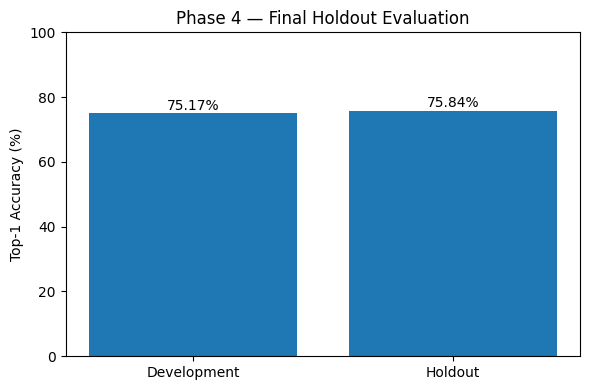

In [29]:
import matplotlib.pyplot as plt

# Final Phase 4 comparison: frozen architecture on Development vs Holdout.
phase4_summary = pd.DataFrame({
    "Split": [
        "Development",
        "Holdout"
    ],
    "Top-1 Accuracy (%)": [
        75.17,
        75.84
    ]
})

plt.figure(figsize=(6, 4))

bars = plt.bar(
    phase4_summary["Split"],
    phase4_summary["Top-1 Accuracy (%)"]
)

plt.ylabel("Top-1 Accuracy (%)")
plt.title("Phase 4 — Final Holdout Evaluation")
plt.ylim(0, 100)

for bar, value in zip(
    bars,
    phase4_summary["Top-1 Accuracy (%)"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{value:.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()

### Phase 4 Conclusion

The frozen architecture achieved:

- **Development:** 75.17% (327/435)
- **Holdout:** 75.84% (113/149)

The difference between Development and Holdout accuracy is only **+0.67
percentage points**.

This close agreement indicates that the selected architecture maintained
similar performance on previously unseen incidents rather than showing a large
drop after Development-based architecture selection.

The Holdout evaluation was performed once after the metric representation,
retrieval configuration, Cross-Encoder reranker, prompt, parser, and LLM
configuration had been frozen.

No further tuning was performed based on Holdout results.